In [2]:
from qiskit import QuantumCircuit
from qiskit.visualization import plot_histogram
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import SamplerV2 as Sampler
import matplotlib.pyplot as plt

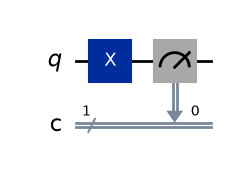

In [3]:
# Circuit A
qc_A = QuantumCircuit(1, 1)
qc_A.x(0)
qc_A.measure(0, 0)

qc_A.draw("mpl")

The initial state is $|0\rangle$. The X gate flips the qubit from $|0\rangle$ to $|1\rangle$.

$$
X|0\rangle = |1\rangle
$$

Prediction: The measurement outcome will be $1$ with 100% probability on an ideal quantum computer.



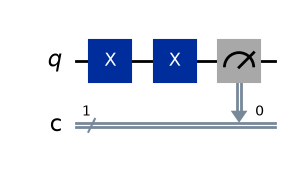

In [5]:
# Circuit B
qc_B = QuantumCircuit(1, 1)
qc_B.x(0)
qc_B.x(0)
qc_B.measure(0, 0)

qc_B.draw("mpl")

The first X gate changes $|0\rangle$ to $|1\rangle$, and the second X gate changes it back to $|0\rangle$.

$$
X(X|0\rangle) = |0\rangle
$$
Prediction: The measurement outcome will be $0$ with 100% probability on an ideal quantum computer.

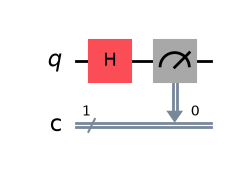

In [6]:
# Circuit C
qc_C = QuantumCircuit(1, 1)
qc_C.h(0)
qc_C.measure(0, 0)

display(qc_C.draw("mpl"))

The Hadamard (H) gate creates an equal superposition of $|0\rangle$ and $|1\rangle$.

$$
H|0\rangle = \frac{|0\rangle + |1\rangle}{\sqrt{2}}
$$

The measurement probabilities are:

$$
P(0) = \frac{1}{2} = 50%
$$

$$
P(1) = \frac{1}{2} = 50%
$$

Prediction: The outcomes $0$ and $1$ will each occur approximately 50% of the time. Circuit C will not always produce the same measurement result.

In [6]:
backend = service.backend("ibm_fez")
print("Selected backend:", backend.name)

Selected backend: ibm_fez


In [7]:
circuits = [qc_A, qc_B, qc_C]

pass_manager = generate_preset_pass_manager(
    backend=backend,
    optimization_level=1
)

isa_circuits = pass_manager.run(circuits)

sampler = Sampler(mode=backend)
job = sampler.run(isa_circuits, shots=100)

print("Job ID:", job.job_id())

result = job.result()
print("Experiment completed!")

C:\Users\surya\AppData\Local\Temp\ipykernel_16784\1017582105.py:10: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)


Job ID: db5nnc84qg6s73c3od9g
Experiment completed!


In [13]:
%matplotlib inline

import matplotlib.pyplot as plt
from qiskit.visualization import plot_histogram

Circuit A: {'1': 98, '0': 2}
Circuit B: {'0': 98, '1': 2}
Circuit C: {'1': 48, '0': 52}


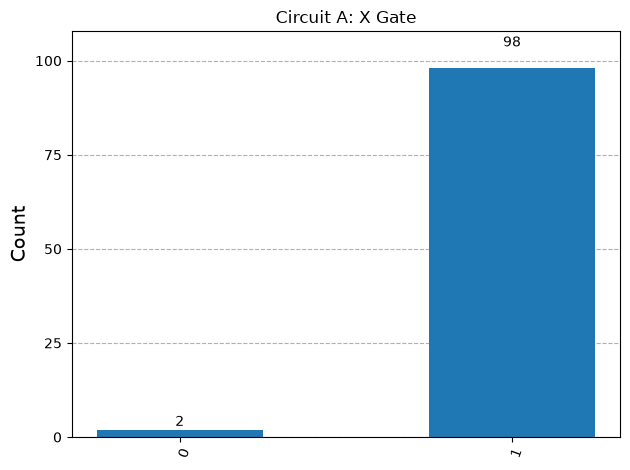

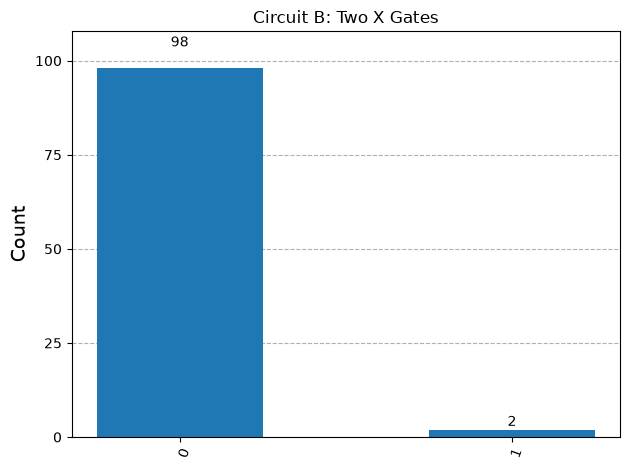

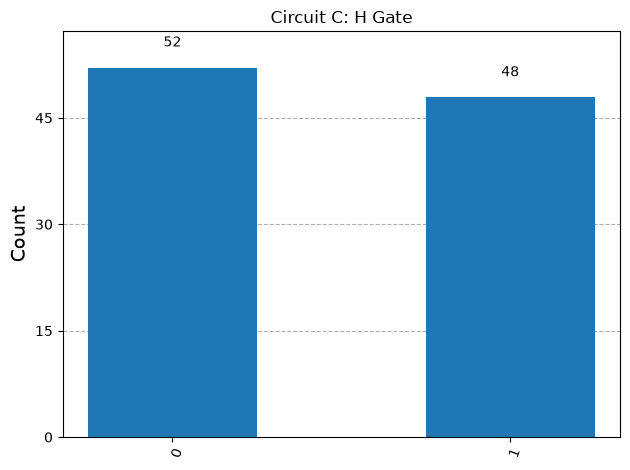

In [15]:
counts_A = result[0].data.c.get_counts()
counts_B = result[1].data.c.get_counts()
counts_C = result[2].data.c.get_counts()

print("Circuit A:", counts_A)
print("Circuit B:", counts_B)
print("Circuit C:", counts_C)

plot_histogram(counts_A, title="Circuit A: X Gate")
plt.show()

plot_histogram(counts_B, title="Circuit B: Two X Gates")
plt.show()

plot_histogram(counts_C, title="Circuit C: H Gate")
plt.show()

Each circuit was executed on IBM Quantum hardware for 100 shots.

A — X gate

100% $1$

$98$ ones, $2$ zeros

Mostly matched the prediction.

B — Two X gates

100% $0$

$98$ zeros, $2$ ones

Mostly matched the prediction.

C — H gate

Approximately 50% each

$52$ zeros, $48$ ones

Closely matched the predicted 50/50 distribution.

$Conclusion:$The experimental results agreed closely with the theoretical predictions. Circuit A demonstrated the bit-flip operation of the X gate, while Circuit B showed that applying two X gates restores the initial state. Circuit C demonstrated superposition, producing approximately equal numbers of $0$ and $1$ outcomes. Small deviations from ideal results may be due to quantum hardware noise and measurement errors.